# 10 - Killing rate vs. protection: is the relation linear?

**Question.** In the two-strain model, is there a linear relation between the killing rate and the
protection of the resistant strain?

**Definitions**

- **Killing rate (y-axis): γ**, the maximum lysis coefficient. The per-capita lysis rate of S is γ · H(a) · g(s).
- **Protection (x-axis): p = 1 − β**, the fraction of that lysis R avoids with the inhibitor present.
  The per-capita lysis rate of R is (1 − p) · γ · H(a) · g(s). p is set through β_min:
  p = (1 − β_min)(1 − c·ι). At the base strain p = 0.031.

**Variation levels**

| Axis | Range | Values | Note |
|---|---|---|---|
| γ | 1.1 - 3.1 | 21 + base (1.38) | the paper's range is 1.1 - 1.4; extended here (group choice) so the shape of the relation can be tested |
| p | 0 - 0.30 | 21 + base (0.031) | 0.307 is the largest p reachable at base c (β_min = 0) |
| α | 0.85, 0.90, 0.95 | 3 | cost of resistance |
| a0 | 2.15 and 100 | 2 | base dose and the top of the paper's dose range |

22 × 22 × 3 × 2 = 2,904 runs with the same engine and endpoints as every other notebook (plain model).

**What the equations say.** Subtracting the per-capita growth rates in S1 and S2:

d ln(n_r / n_s) / dt = g(s) · [ γ · H(a) · p − (1 − α) ]

So at any moment R gains when γ · H · p > 1 − α. Three tests follow from this:

1. Is the lysis rate of R linear in protection? (yes by construction; checked)
2. Is the neutral line, where R neither gains nor loses, a straight line in the (γ, p) plane?
3. Is the killing each strain actually suffers over a run linear in protection?

In [1]:
from pathlib import Path
import sys, time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

PROJECT_ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "src").is_dir())
sys.path.insert(0, str(PROJECT_ROOT))
TABLES = PROJECT_ROOT / "results" / "tables"
TABLES.mkdir(parents=True, exist_ok=True)
pd.set_option("display.max_columns", None); pd.set_option("display.width", 160)

from src.analysis import kill_protection as kp
from src.analysis.kill_protection import (GAMMA_AXIS, PROTECTION_AXIS, ALPHAS, DOSES, BASE_PROTECTION,
                                          P_MAX, linear_fit, regrowth_prediction)
from src.analysis.plotting import OKABE_ITO
from src.model.ma2024_model import DEFAULT_PARAMS

FORCE_RERUN = False
def run_or_load(name, runner):
    path = TABLES / name
    if path.exists() and not FORCE_RERUN:
        return pd.read_csv(path)
    t0 = time.time(); out = runner(); out.to_csv(path, index=False, float_format="%.8g")
    print(f"{name}: {len(out):,} rows in {time.time() - t0:.0f} s"); return out

df = run_or_load("grid_gamma_protection.csv", kp.run_plane)
neutral = run_or_load("neutral_lines_gamma_protection.csv", kp.run_neutral_lines)
BASE_GAMMA = DEFAULT_PARAMS.gamma
print(f"{len(df):,} runs; all settled: {bool(df.ss_converged.all())}; base point: γ = {BASE_GAMMA}, p = {BASE_PROTECTION:.4f}")
print(f"γ levels: {len(GAMMA_AXIS)} ({GAMMA_AXIS.min():g}-{GAMMA_AXIS.max():g}); p levels: {len(PROTECTION_AXIS)} ({PROTECTION_AXIS.min():g}-{PROTECTION_AXIS.max():g})")

2,904 runs; all settled: True; base point: γ = 1.38, p = 0.0307
γ levels: 22 (1.1-3.1); p levels: 22 (0-0.3)


## Test 1 - Lysis rate of R against protection

Per-capita lysis rates at the start of treatment. The protection rate is the lysis R avoids per unit
time, p · γ · H(a0) · g(s0).

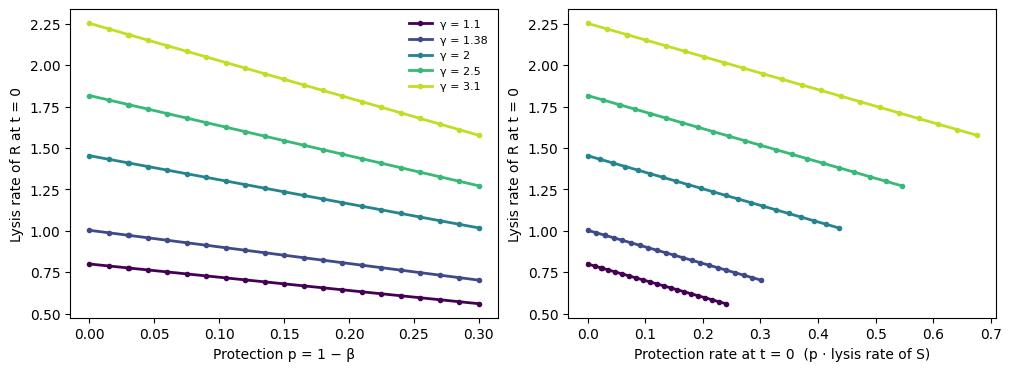

,slope,intercept,r2
γ,,,
1.10,-0.7995,0.7995,1.0
1.38,-1.0031,1.0031,1.0
2.00,-1.4537,1.4537,1.0
2.50,-1.8172,1.8172,1.0
3.10,-2.2533,2.2533,1.0


In [2]:
sel = df[(df.a0 == 2.15) & (df.alpha == 0.95)]
gammas = [1.1, 1.38, 2.0, 2.5, 3.1]
shades = plt.cm.viridis(np.linspace(0.0, 0.9, len(gammas)))
fig, axes = plt.subplots(1, 2, figsize=(10, 3.6), constrained_layout=True)
for g, col in zip(gammas, shades):
    s = sel[np.isclose(sel.gamma, g)].sort_values("protection")
    axes[0].plot(s.protection, s.lysis0_R, color=col, lw=2, marker="o", ms=3, label=f"γ = {g:g}")
    axes[1].plot(s.protection_rate0, s.lysis0_R, color=col, lw=2, marker="o", ms=3)
axes[0].set(xlabel="Protection p = 1 − β", ylabel="Lysis rate of R at t = 0")
axes[1].set(xlabel="Protection rate at t = 0  (p · lysis rate of S)", ylabel="Lysis rate of R at t = 0")
axes[0].legend(frameon=False, fontsize=8)
plt.show()
fits = pd.DataFrame([{"γ": g, **linear_fit(sel[np.isclose(sel.gamma, g)].protection, sel[np.isclose(sel.gamma, g)].lysis0_R)} for g in gammas]).set_index("γ")
fits[["slope", "intercept", "r2"]].round(4)

## Test 2 - The neutral line in the (γ, p) plane

Colour: change in ln(R/S) after regrowth (above 0 = R gained). White dashed line: where the simulation
gives exactly 0 after regrowth. Black dotted line: the saturating-drug prediction p = (1 − α)/γ. Thin white
line (bottom row): where the simulation gives 0 when read during treatment (t = 100). Red cross: base point (α = 0.95, base dose).
Top row: base dose. Bottom row: a0 = 100.

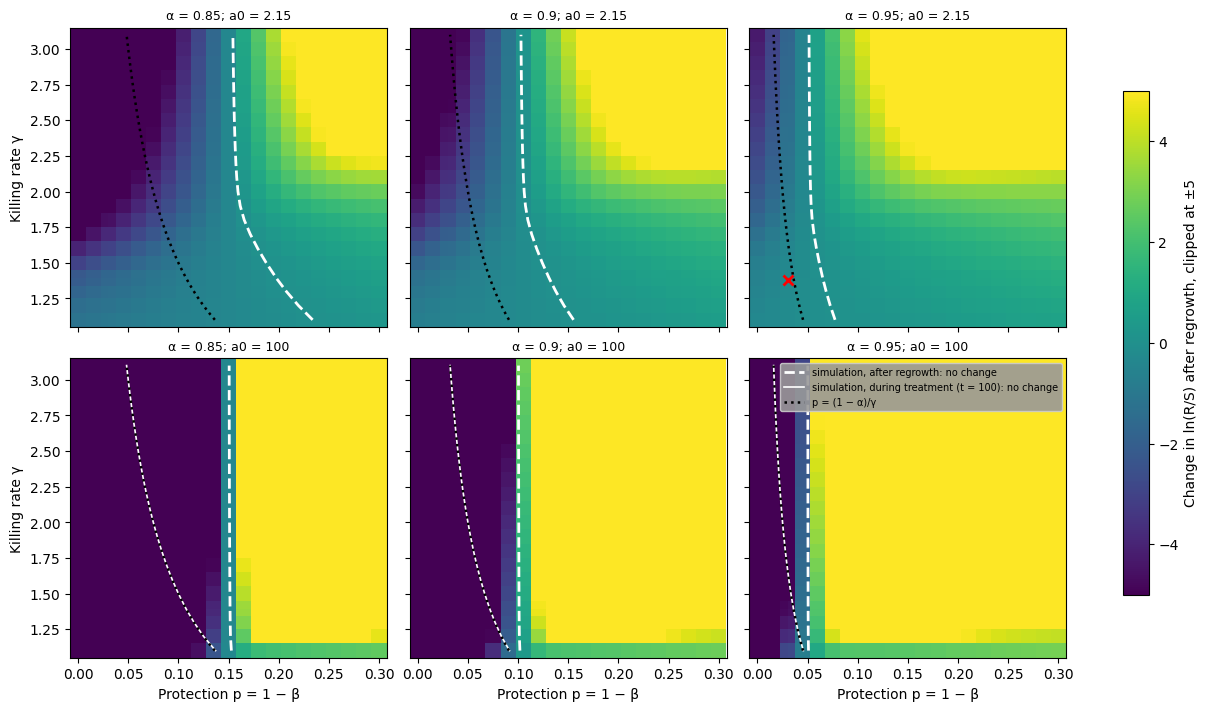

In [3]:
def plane(ax, sub, value, vmin, vmax):
    piv = sub.pivot(index="gamma", columns="protection", values=value)
    return ax.pcolormesh(piv.columns, piv.index, piv.values.clip(vmin, vmax), cmap="viridis", vmin=vmin, vmax=vmax, shading="nearest")

fig, axes = plt.subplots(2, 3, figsize=(12, 7), constrained_layout=True, sharex=True, sharey=True)
gg = np.linspace(GAMMA_AXIS.min(), GAMMA_AXIS.max(), 200)
for j, al in enumerate(ALPHAS):
    for r, a0 in enumerate(DOSES):
        ax = axes[r, j]
        im = plane(ax, df[(df.a0 == a0) & (df.alpha == al)], "delta_log_ratio", -5, 5)
        nl = neutral[(neutral.a0 == a0) & (neutral.readout == "final") & (neutral.alpha == al)].sort_values("gamma")
        ax.plot(nl.p_neutral, nl.gamma, color="white", ls="--", lw=2, label="simulation, after regrowth: no change")
        if a0 == 100.0:
            nt = neutral[(neutral.a0 == a0) & (neutral.readout == "100") & (neutral.alpha == al)].sort_values("gamma")
            ax.plot(nt.p_neutral, nt.gamma, color="white", ls="-", lw=1.2, label="simulation, during treatment (t = 100): no change")
        ax.plot((1 - al) / gg, gg, color="black", ls=":", lw=1.8, label="p = (1 − α)/γ")
        if al == DEFAULT_PARAMS.alpha and a0 == 2.15:        # the base point exists only in this panel
            ax.plot(BASE_PROTECTION, BASE_GAMMA, marker="x", color="red", ms=7, mew=2)
        ax.set_xlim(-0.008, 0.308); ax.set_title(f"α = {al:g}; a0 = {a0:g}", fontsize=9)
        if r == 1: ax.set_xlabel("Protection p = 1 − β")
        if j == 0: ax.set_ylabel("Killing rate γ")
axes[1, 2].legend(fontsize=7, loc="upper right", facecolor="0.6", framealpha=0.9)
fig.colorbar(im, ax=axes, shrink=0.8, label="Change in ln(R/S) after regrowth, clipped at ±5")
plt.show()

### Is the neutral line straight?

For each cost of resistance and read-out: a straight-line fit of the neutral protection against γ, and
against 1/γ. "Largest deviation" is the largest distance from the fitted line as a fraction of the range.

In [4]:
rows = []
for (a0, readout, al), g in neutral.groupby(["a0", "readout", "alpha"]):
    f1, f2 = linear_fit(g.gamma, g.p_neutral), linear_fit(1 / g.gamma, g.p_neutral)
    rows.append({"dose a0": a0, "read-out": "after regrowth" if readout == "final" else "during treatment (t = 100)", "α": al,
                 "neutral p at γ = 1.1": g.p_neutral.iloc[0], "neutral p at γ = 3.1": g.p_neutral.iloc[-1],
                 "R² vs γ": f1["r2"], "largest deviation vs γ": f1["max_dev"],
                 "R² vs 1/γ": f2["r2"], "slope vs 1/γ": f2["slope"], "1 − α": 1 - al,
                 "largest |p − (1 − α)/γ|": (g.p_neutral - g.p_criterion).abs().max()})
fit_table = pd.DataFrame(rows).set_index(["dose a0", "read-out", "α"]).round(4)
fit_table

neutral p at γ = 1.1  neutral p at γ = 3.1  R² vs γ  largest deviation vs γ  R² vs 1/γ  slope vs 1/γ  1 − α  \
dose a0 read-out                   α                                                                                                                   
2.15    after regrowth             0.85                0.2338                0.1543   0.7304                  0.3698     0.9236        0.1331   0.15   
                                   0.90                0.1553                0.1029   0.7201                  0.3794     0.9173        0.0869   0.10   
                                   0.95                0.0774                0.0514   0.7107                  0.3882     0.9112        0.0426   0.05   
100.00  during treatment (t = 100) 0.85                0.1371                0.0484   0.9275                  0.2042     1.0000        0.1505   0.15   
                                   0.90                0.0914                0.0323   0.9273                  0.2047     1.0000        0.1003   0.10   
                                   0.95                0.0457                0.0161   0.9272                  0.2053     1.0000        0.0502   0.05   
        after regrowth             0.85                0.1528                0.1506   0.7427                  0.4552     0.9028        0.0029   0.15   
                                   0.90                0.1018                0.1004   0.7604                  0.4395     0.9163        0.0019   0.10   
                                   0.95                0.0509                0.0502   0.7745                  0.4265     0.9267        0.0009   0.05   

                                         largest |p − (1 − α)/γ|  
dose a0 read-out                   α                              
2.15    after regrowth             0.85                   0.1060  
                                   0.90                   0.0706  
                                   0.95                   0.0353  
100.00  during treatment (t = 100) 0.85                   0.0007  
                                   0.90                   0.0005  
                                   0.95                   0.0003  
        after regrowth             0.85                   0.1022  
                                   0.90                   0.0682  
                                   0.95                   0.0341

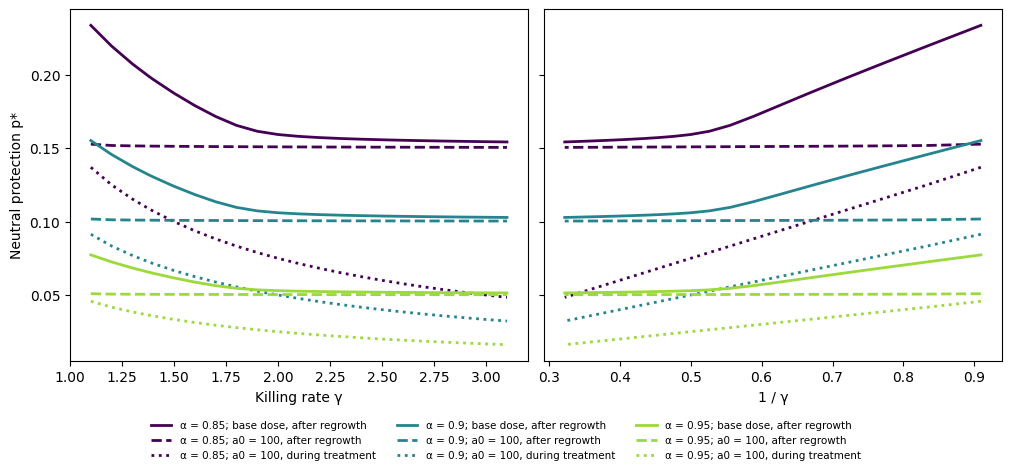

In [5]:
fig, axes = plt.subplots(1, 2, figsize=(10, 4.6), constrained_layout=True, sharey=True)
styles = {(2.15, "final"): ("-", "base dose, after regrowth"), (100.0, "final"): ("--", "a0 = 100, after regrowth"),
          (100.0, "100"): (":", "a0 = 100, during treatment")}
for al, col in zip(ALPHAS, plt.cm.viridis([0.0, 0.45, 0.85])):
    for (a0, readout), (ls, lab) in styles.items():
        g = neutral[(neutral.a0 == a0) & (neutral.readout == readout) & (neutral.alpha == al)].sort_values("gamma")
        axes[0].plot(g.gamma, g.p_neutral, color=col, ls=ls, lw=2, label=f"α = {al:g}; {lab}")
        axes[1].plot(1 / g.gamma, g.p_neutral, color=col, ls=ls, lw=2)
axes[0].set(xlabel="Killing rate γ", ylabel="Neutral protection p*"); axes[1].set(xlabel="1 / γ")
fig.legend(*axes[0].get_legend_handles_labels(), loc="outside lower center", ncol=3, frameon=False, fontsize=7.5)
plt.show()

### Why the neutral line flattens after regrowth

Integrating the identity over a whole run gives an exact result:

p* = (1 − α) / (1 − ΔlnS / G),   G = ∫ g(s) dt (total growth),  ΔlnS = ln(final S / starting S)

When the drug kills a lot and the culture then regrows, G is much larger than ΔlnS, so p* → 1 − α:
over a full kill-and-regrow cycle, total lysis equals total growth, whatever γ is.

In [6]:
rows = []
for a0 in DOSES:
    for g in (1.1, 1.38, 2.0, 3.1):
        r = neutral[(neutral.a0 == a0) & (neutral.readout == "final") & (neutral.alpha == 0.95) & np.isclose(neutral.gamma, g)].iloc[0]
        pred = regrowth_prediction(g, r.p_neutral, 0.95, a0)
        rows.append({"dose a0": a0, "γ": g, "neutral p (simulation)": r.p_neutral, "neutral p (formula)": pred["p_predicted"],
                     "total growth G": pred["G"], "ΔlnS": pred["dlnS"], "(1 − α)/γ": 0.05 / g})
check = pd.DataFrame(rows).set_index(["dose a0", "γ"])
print(f"Largest difference between simulation and formula: {(check['neutral p (simulation)'] - check['neutral p (formula)']).abs().max():.1e}  (α = 0.95)")
check.round(4)

Largest difference between simulation and formula: 3.4e-07  (α = 0.95)


neutral p (simulation)  neutral p (formula)  total growth G    ΔlnS  (1 − α)/γ
dose a0 γ                                                                                   
2.15    1.10                  0.0774               0.0774          6.4490  2.2810     0.0455
        1.38                  0.0655               0.0655          9.5790  2.2684     0.0362
        2.00                  0.0530               0.0530         41.6707  2.3277     0.0250
        3.10                  0.0514               0.0514         84.7207  2.3663     0.0161
100.00  1.10                  0.0509               0.0509        121.9200  2.1301     0.0455
        1.38                  0.0505               0.0505        231.6558  2.3287     0.0362
        2.00                  0.0503               0.0503        357.0144  2.3608     0.0250
        3.10                  0.0502               0.0502        563.0940  2.3707     0.0161

## Test 3 - Killing actually suffered, against protection

- **Peak death rate:** the fastest net per-capita decline during the run.
- **Log kill:** ln(starting density / lowest density), the depth of the crash.

Lines: one value of γ each (α = 0.95). Top: base dose. Bottom: a0 = 100.

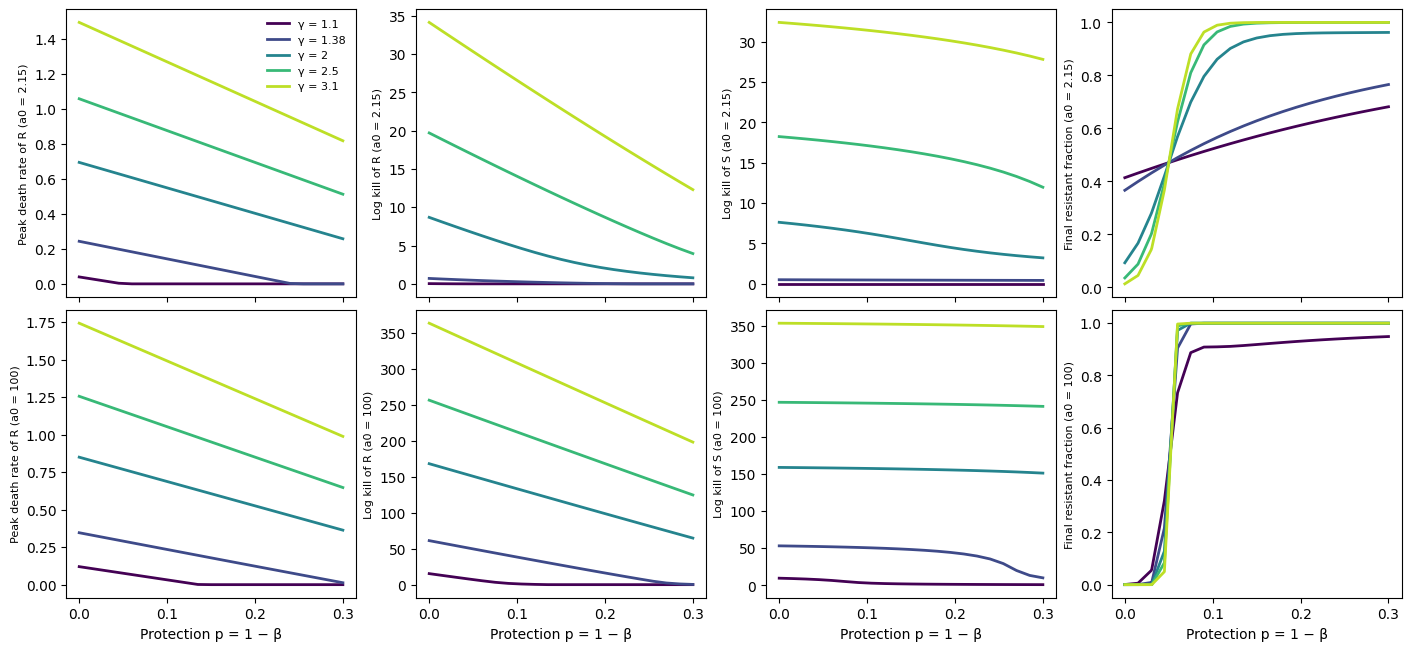

In [7]:
fig, axes = plt.subplots(2, 4, figsize=(14, 6.4), constrained_layout=True, sharex=True)
cols = [("peak_death_R", "Peak death rate of R"), ("log_kill_R", "Log kill of R"),
        ("log_kill_S", "Log kill of S"), ("f_R_final", "Final resistant fraction")]
for r, a0 in enumerate(DOSES):
    sel = df[(df.a0 == a0) & (df.alpha == 0.95)]
    for g, col in zip(gammas, shades):
        s = sel[np.isclose(sel.gamma, g)].sort_values("protection")
        for ax, (y, lab) in zip(axes[r], cols):
            ax.plot(s.protection, s[y], color=col, lw=2, label=f"γ = {g:g}")
    for ax, (y, lab) in zip(axes[r], cols):
        ax.set_ylabel(lab + f" (a0 = {a0:g})", fontsize=8)
        if r == 1: ax.set_xlabel("Protection p = 1 − β")
axes[0, 0].legend(frameon=False, fontsize=8)
plt.show()

In [8]:
rows = []
for a0 in DOSES:
    for g in GAMMA_AXIS:
        s = df[(df.a0 == a0) & (df.alpha == 0.95) & np.isclose(df.gamma, g)]
        rows.append({"dose a0": a0, "γ": g, **{lab: linear_fit(s.protection, s[y])["r2"] for y, lab in
                    [("lysis0_R", "lysis rate of R at t = 0"), ("peak_death_R", "peak death rate of R"),
                     ("log_kill_R", "log kill of R"), ("log_kill_S", "log kill of S"),
                     ("delta_log_ratio", "change in ln(R/S)"), ("f_R_final", "final f_R")]}})
r2 = pd.DataFrame(rows).set_index(["dose a0", "γ"])
print("R² of a straight-line fit against protection, for each γ (α = 0.95):")
display(r2.loc[(slice(None), [1.1, 1.2, 1.38, 1.6, 2.0, 2.5, 3.1]), :].round(3))
print("Number of γ levels (of 22) with R² ≥ 0.99:")
(r2 >= 0.99).groupby(level=0).sum()

R² of a straight-line fit against protection, for each γ (α = 0.95):


lysis rate of R at t = 0  peak death rate of R  log kill of R  log kill of S  change in ln(R/S)  final f_R
dose a0 γ                                                                                                               
2.15    1.10                       1.0                 0.395          0.295            NaN              0.995      0.992
        1.20                       1.0                 0.750          0.648          1.000              0.992      0.988
        1.38                       1.0                 0.980          0.904          0.995              0.983      0.973
        1.60                       1.0                 1.000          0.951          0.977              0.951      0.920
        2.00                       1.0                 1.000          0.960          0.995              0.821      0.714
        2.50                       1.0                 1.000          0.999          0.948              0.969      0.640
        3.10                       1.0                 1.000          1.000          0.972              0.998      0.600
100.00  1.10                       1.0                 0.773          0.651          0.811              0.568      0.580
        1.20                       1.0                 0.940          0.869          0.940              0.277      0.524
        1.38                       1.0                 1.000          0.996          0.754              0.604      0.525
        1.60                       1.0                 1.000          1.000          0.879              0.996      0.518
        2.00                       1.0                 1.000          1.000          0.950              1.000      0.511
        2.50                       1.0                 1.000          1.000          0.970              1.000      0.507
        3.10                       1.0                 1.000          1.000          0.978              1.000      0.504

Number of γ levels (of 22) with R² ≥ 0.99:


,lysis rate of R at t = 0,peak death rate of R,log kill of R,log kill of S,change in ln(R/S),final f_R
dose a0,,,,,,
2.15,22,17,9,5,7,1
100.00,22,20,19,0,16,0


## Killing of R against killing of S

One dot per run (all γ and p, α = 0.95). Dashed: equal killing.

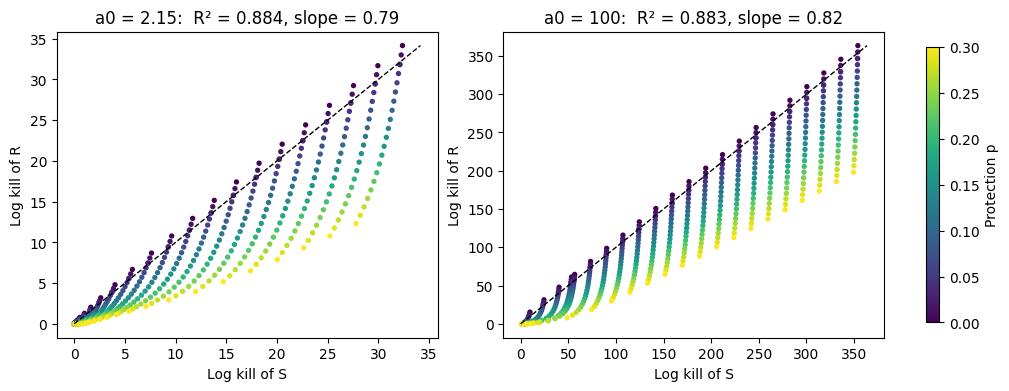

n     R²  slope
dose a0 runs                                    
2.15    all runs               484  0.884  0.791
        p = 0 (no protection)   22  1.000  1.053
        p = 0.30                22  0.989  0.428
100.00  all runs               484  0.883  0.820
        p = 0 (no protection)   22  1.000  1.008
        p = 0.30                22  0.985  0.577

In [9]:
fig, axes = plt.subplots(1, 2, figsize=(10, 3.8), constrained_layout=True)
for ax, a0 in zip(axes, DOSES):
    s = df[(df.a0 == a0) & (df.alpha == 0.95)]
    sc = ax.scatter(s.log_kill_S, s.log_kill_R, c=s.protection, cmap="viridis", s=8, vmin=0, vmax=0.3)
    lim = max(s.log_kill_S.max(), s.log_kill_R.max()); ax.plot([0, lim], [0, lim], color="black", ls="--", lw=1)
    f = linear_fit(s.log_kill_S, s.log_kill_R)
    ax.set(xlabel="Log kill of S", ylabel="Log kill of R", title=f"a0 = {a0:g}:  R² = {f['r2']:.3f}, slope = {f['slope']:.2f}")
fig.colorbar(sc, ax=axes, shrink=0.9, label="Protection p")
plt.show()
rows = []
for a0 in DOSES:
    s = df[(df.a0 == a0) & (df.alpha == 0.95)]
    for lab, sub in [("all runs", s), ("p = 0 (no protection)", s[s.protection == 0]), ("p = 0.30", s[np.isclose(s.protection, 0.30)])]:
        f = linear_fit(sub.log_kill_S, sub.log_kill_R)
        rows.append({"dose a0": a0, "runs": lab, "n": f["n"], "R²": f["r2"], "slope": f["slope"]})
pd.DataFrame(rows).set_index(["dose a0", "runs"]).round(3)

## Takeaways

- **Rates: exactly linear.** The lysis rate of R is (1 − p) times the lysis rate of S, so it falls on a
  straight line against protection for every γ (R² = 1, slope = −γ·H(a0)·g(s0)). This is how the
  model is built, not a finding.
- **Killing rate and protection trade off inversely, not linearly, during treatment.** The neutral
  protection is p* = (1 − α)/γ (simulation within 0.0007 of it at a0 = 100, t = 100). It is a straight
  line against 1/γ (R² = 1.0000) and a curve against γ (R² = 0.93; up to 21% of the range off a straight line).
- **After regrowth the killing rate almost stops mattering.** Over a full kill-and-regrow cycle the
  neutral protection is p* = (1 − α)/(1 − ΔlnS/G) exactly (simulation and formula agree to 3 × 10⁻⁷;
  G and ΔlnS are taken from the same run, so this is a consistency relation, not a prediction).
  With strong killing it tends to 1 − α whatever γ is: at a0 = 100, p* stays at 0.050–0.051 from γ = 1.1
  to 3.1 (α = 0.95). At the base dose it bends from 0.077 to 0.051.
- **Cost of resistance sets the scale.** In every read-out p* is close to proportional to 1 − α (within
  0.1% at a0 = 100 in both read-outs; within 1.5% after regrowth at the base dose).
- **Killing actually suffered by R is linear in protection only when killing is strong.** Peak death rate
  of R: R² ≥ 0.99 in 17 of 22 γ levels at the base dose and 20 of 22 at a0 = 100. Log kill of R: 9 of 22
  and 19 of 22. Weaker killing is not linear: γ ≤ 1.4 (peak death rate) and γ ≤ 2.2 (log kill) at the base
  dose, γ ≤ 1.3 at a0 = 100. There the lines flatten to zero once R is protected enough to stop declining.
- **Killing of S falls as R's protection rises, and not linearly.** More surviving R cells remove the
  antibiotic sooner. From p = 0 to 0.30 the log kill of S falls by 5–58% at the base dose; at a0 = 100 it
  falls up to ten-fold for γ ≤ 1.4 and by less than 5% for γ ≥ 2.0 (8% at γ = 1.8). A straight line fits with R² ≥ 0.99
  in 5 of 22 γ levels at the base dose and in none at a0 = 100.
- **Final resistant fraction is not linear in protection when killing is strong:** for γ ≥ 1.6 or at
  a0 = 100 it is a steep S-shaped switch around p*. At the base dose with γ = 1.1–1.4 (the paper's range)
  it rises smoothly (R² = 0.97–0.99).
- **R and S are killed together.** Without protection the log kill of R runs parallel to that of S
  (slope 1.01–1.05, R² = 1.000) but is larger, by 0.03–1.8 ln units at the base dose and 6–10 at
  a0 = 100, because of R's growth cost. At p = 0.30 the slope falls to 0.43–0.58. Over all runs R² = 0.88.

**Limits.** γ is extended beyond the paper's 1.1–1.4 to make the shape testable; inside 1.1–1.4 alone the
neutral line moves by only 0.01 in p for α = 0.95 (0.03–0.04 for α = 0.85) and looks straight. Plain
model, no extinction floor. c, the inhibitor dose and all other parameters at base. α = 0.95 for Test 3.